16 ['0.2281', '0.05299', '0.003426']
32 ['1.327', '0.2541', '0.01535']
64 ['7.316', '1.196', '0.06946']
128 ['38.67', '5.531', '0.3143']


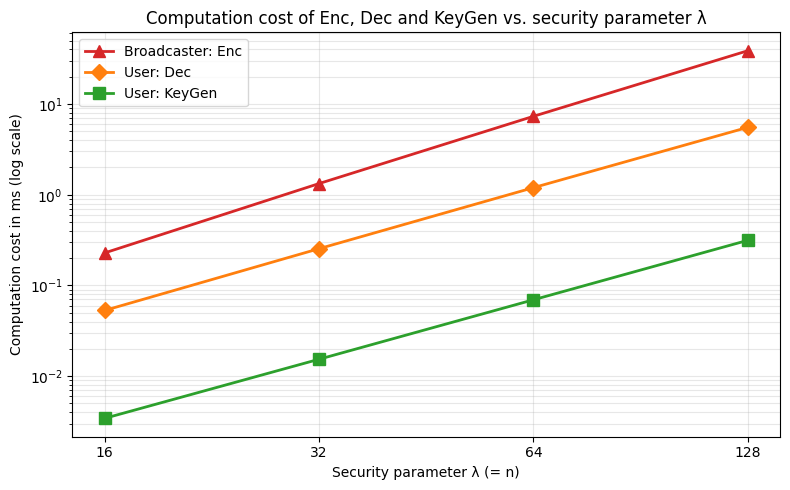

In [ ]:
import math
import matplotlib.pyplot as plt

# ---- unit times in seconds (measured in the sandbox with numpy) ----
t_ma = 0.885e-9   # one multiply-add in Z_p
t_g  = 18.4e-9    # one Gaussian sample
t_b  = 3.61e-9    # one uniform / random-bit sample
t_H  = 430e-9     # one hash
S = 16            # |S|, size of the receiver set (assumption)

def costs_ms(lam):
    n = lam
    k = math.ceil(math.log2(n))
    m = 3 * n * k

    # KeyGen (user)
    keygen = (n*m + n)*t_ma + m*t_b

    # Enc (broadcaster)
    enc_ma = (n*m + S*m) + n*S + S*n*m + (n*m + m) + (2*n*m + m*m) + (n + m + 1)
    enc = enc_ma*t_ma + m*t_g + (m*m + m + lam + n)*t_b + t_H

    # Dec (user)
    dec_ma = n*m + n*S + S*n*m + (n*m + S*m) + (m + 2*m + m + 2)
    dec = dec_ma*t_ma + t_H

    return [enc*1e3, dec*1e3, keygen*1e3]   # milliseconds

lams = [16, 32, 64, 128]
vals = [costs_ms(l) for l in lams]
names = ["Broadcaster: Enc", "User: Dec", "User: KeyGen"]
styles = [("tab:red", "^"), ("tab:orange", "D"), ("tab:green", "s")]

for l, v in zip(lams, vals):
    print(l, ["%.4g" % x for x in v])

x = list(range(len(lams)))
fig, ax = plt.subplots(figsize=(8, 5))
for idx, (name, (c, mk)) in enumerate(zip(names, styles)):
    ax.plot(x, [v[idx] for v in vals], color=c, marker=mk, markersize=8,
            linewidth=2, label=name)

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels([str(l) for l in lams])
ax.set_xlabel("Security parameter λ (= n)")
ax.set_ylabel("Computation cost in ms (log scale)")
ax.set_title("Computation cost of Enc, Dec and KeyGen vs. security parameter λ")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("cost_enc_dec_keygen.png", dpi=150)   # saves the file
plt.show()                                        # opens the graph window